# Stage 10: The out-of-sample test

This is the first use of the 36 months held back since Stage 0. The method, the costs and the decision
rules were fixed in `reports/stage10_protocol.md` before these results were calculated.

Unlike earlier tests, holdings drift between yearly rebalances, and every trade pays costs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models, stats
from pmo import frontier as fr
from pmo import performance as perf
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import asset_class_prices, load
from pmo.plotting import FIGURES, MUTED, PALETTE, SERIES_1, SERIES_2, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy
HAIRCUT = config.survivorship_haircut
CAPPED = fr.Constraints(upper=0.10)
POLICIES = {"Cautious": (0.25, 0.15, 0.60), "Balanced": (0.60, 0.20, 0.20), "Growth": (0.80, 0.10, 0.10)}

rf = data.risk_free["rf"]
other = ret.monthly_returns(ret.complete_month_prices(asset_class_prices().ffill(),
                                                      data.prices.index.max()))
total = data.returns[stocks + [market]].copy()
total["Gold"] = other["Gold"].reindex(total.index)
total["Bonds"] = other["Bonds"].reindex(total.index)
total["Cash"] = rf
holdout = data.periods.index[data.periods == "holdout"]
tested = total.loc[holdout]
rebalance_dates = list(holdout[::12])

COSTS = pd.Series({**{s: 0.002 for s in stocks}, market: 0.0005, "Gold": 0.0005})
TAX = pd.Series({**{s: 0.125 for s in stocks}, market: 0.125, "Gold": 0.125, "Bonds": 0.30})
print(f"{len(holdout)} months, {holdout[0]:%b %Y} to {holdout[-1]:%b %Y}; "
      f"rebalances before {[f'{d:%b %Y}' for d in rebalance_dates]}")

36 months, Nov 2023 to Oct 2026; rebalances before ['Nov 2023', 'Nov 2024', 'Nov 2025']


## 1. Build each portfolio from data available at the time

In [2]:
def training(date):
    return data.excess.loc[data.excess.index < date].iloc[-60:]


def fitted_inputs(train):
    rate = rf.loc[train.index].mean() * 12
    premium = data.factors_long.loc[:train.index.max(), "MKT_RF"].mean()
    mean, cov = fr.annualize(*models.practical_inputs(train[stocks], train[market], premium), rate)
    return mean, cov, rate


def fund_weights(train):
    mean, cov, rate = fitted_inputs(train)
    return fr.solve_max_sharpe(mean - HAIRCUT, cov, rate, CAPPED)


def lowest_risk_weights(train):
    mean, cov, _ = fitted_inputs(train)
    return fr.solve_min_variance(mean, cov, None, CAPPED)


def policy(sleeve, weights):
    equity, gold, bonds = weights
    return pd.concat([sleeve * equity, pd.Series({"Gold": gold, "Bonds": bonds})])


def schedule(builder):
    return {date: builder(training(date)).pipe(lambda w: w[w.abs() > 1e-6]) for date in rebalance_dates}


nifty = pd.Series({market: 1.0})
equal = pd.Series(1 / len(stocks), index=stocks)
plans = {
    "Stock fund": schedule(fund_weights),
    "Capped lowest risk": schedule(lowest_risk_weights),
    "Equal weight": schedule(lambda train: equal),
    "Market tracker": schedule(lambda train: fr.tracking_portfolio(train[market], train[stocks])),
    "Nifty": schedule(lambda train: nifty),
}
for name, weights in POLICIES.items():
    plans[f"{name}, stock fund"] = {d: policy(w, weights) for d, w in plans["Stock fund"].items()}
    plans[f"{name}, Nifty"] = {d: policy(w, weights) for d, w in plans["Nifty"].items()}

STOCK_LEVEL = ["Stock fund", "Capped lowest risk", "Equal weight", "Market tracker", "Nifty"]
holdings = pd.DataFrame({d.strftime("%b %Y"): w.round(3) for d, w in plans["Stock fund"].items()}).fillna(0)
print("Stocks held at each rebalance:", (holdings > 0).sum().to_dict())
holdings[(holdings.max(axis=1) > 0)].sort_values(holdings.columns[0], ascending=False)

Stocks held at each rebalance: {'Nov 2023': 17, 'Nov 2024': 12, 'Nov 2025': 12}


,Nov 2023,Nov 2024,Nov 2025
ASIANPAINT,0.100,0.000,0.000
DRREDDY,0.100,0.100,0.000
BHARTIARTL,0.100,0.100,0.100
HCLTECH,0.100,0.100,0.000
NESTLEIND,0.100,0.000,0.000
TITAN,0.100,0.000,0.000
ULTRACEMCO,0.077,0.037,0.000
INFY,0.073,0.099,0.000
HINDUNILVR,0.047,0.000,0.000
BAJAJ-AUTO,0.042,0.100,0.075


## 2. Results after costs

In [3]:
gross = {name: backtest.simulate(tested, plan, pd.Series(dtype=float)) for name, plan in plans.items()}
net = {name: backtest.simulate(tested, plan, COSTS) for name, plan in plans.items()}
taxed = {name: backtest.simulate(tested, plan, COSTS, TAX) for name, plan in plans.items()}
excess_net = pd.DataFrame({name: sim.returns for name, sim in net.items()}).sub(rf.loc[holdout], axis=0)

card = perf.scorecard(excess_net, excess_net["Nifty"])
card["cagr"] = [stats.geometric_return(net[name].returns) for name in card.index]
card["turnover"] = [net[name].turnover for name in card.index]
card["cost_per_year"] = [net[name].costs / 3 for name in card.index]
card["gross_cagr"] = [stats.geometric_return(gross[name].returns) for name in card.index]
card["after_tax_cagr"] = [stats.geometric_return(taxed[name].returns) for name in card.index]
columns = ["cagr", "gross_cagr", "after_tax_cagr", "volatility", "sharpe", "beta", "alpha", "alpha_t",
           "max_drawdown", "turnover", "cost_per_year"]
card[columns].round(3)

,cagr,gross_cagr,after_tax_cagr,volatility,sharpe,beta,alpha,alpha_t,max_drawdown,turnover,cost_per_year
Stock fund,0.064,0.066,0.059,0.152,0.098,1.015,-0.009,-0.237,-0.236,0.462,0.002
Capped lowest risk,0.039,0.040,0.035,0.150,-0.066,0.994,-0.033,-1.118,-0.300,0.297,0.001
Equal weight,0.100,0.101,0.097,0.143,0.329,1.013,0.023,1.281,-0.181,0.221,0.001
Market tracker,0.081,0.082,0.078,0.141,0.208,1.015,0.005,0.419,-0.208,0.253,0.001
Nifty,0.076,0.076,0.076,0.137,0.173,1.000,-0.000,-0.295,-0.199,0.167,0.000
"Cautious, stock fund",0.100,0.101,0.098,0.060,0.648,0.346,0.030,1.430,-0.084,0.261,0.001
"Cautious, Nifty",0.103,0.103,0.102,0.058,0.714,0.337,0.033,1.703,-0.078,0.195,0.000
"Balanced, stock fund",0.114,0.115,0.109,0.103,0.532,0.645,0.039,1.201,-0.121,0.357,0.001
"Balanced, Nifty",0.121,0.121,0.119,0.096,0.629,0.629,0.045,1.949,-0.112,0.194,0.000
"Growth, stock fund",0.089,0.091,0.084,0.125,0.278,0.829,0.015,0.455,-0.167,0.409,0.002


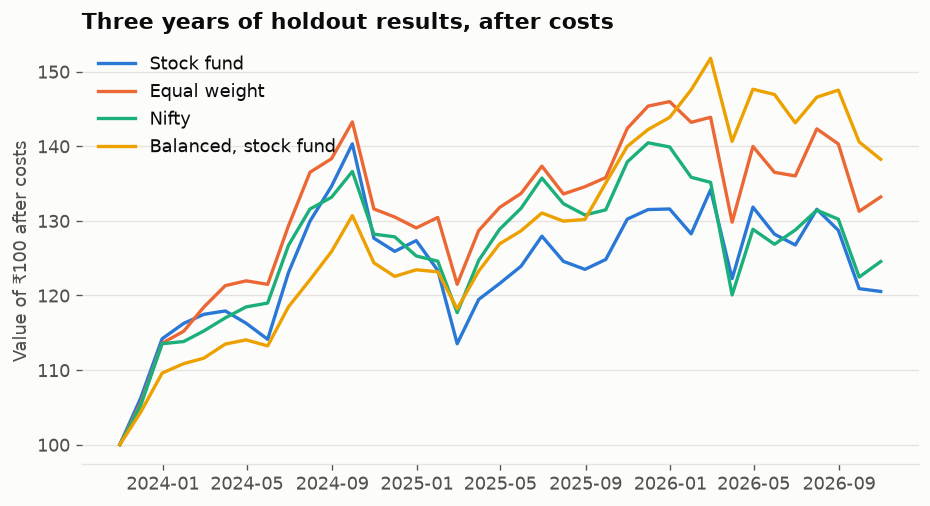

In [4]:
growth = (1 + pd.DataFrame({name: net[name].returns for name in
                            ["Stock fund", "Equal weight", "Nifty", "Balanced, stock fund"]})).cumprod() * 100
growth = pd.concat([pd.DataFrame(100.0, index=[holdout[0] - pd.offsets.MonthEnd(1)], columns=growth.columns), growth])
fig, ax = plt.subplots(figsize=(9, 4.6))
for name, color in zip(growth.columns, PALETTE):
    ax.plot(growth.index, growth[name], color=color, label=name)
ax.set_ylabel("Value of ₹100 after costs")
ax.set_title("Three years of holdout results, after costs")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "10_holdout_growth.png")
plt.show()

## 3. Against a fair benchmark and against chance

In [5]:
tracker = excess_net["Market tracker"]
fair = perf.scorecard(excess_net[["Stock fund", "Capped lowest risk", "Equal weight"]], tracker)
fair = fair[["beta", "alpha", "alpha_t", "information_ratio"]]
bounds = {name: perf.alpha_interval(excess_net[name], tracker, block=3) for name in fair.index}
fair["alpha_low"] = [bounds[name][0] for name in fair.index]
fair["alpha_high"] = [bounds[name][1] for name in fair.index]
fair.round(3)

,beta,alpha,alpha_t,information_ratio,alpha_low,alpha_high
Stock fund,0.955,-0.013,-0.301,-0.185,-0.092,0.084
Capped lowest risk,0.984,-0.039,-1.282,-0.678,-0.102,0.030
Equal weight,0.982,0.018,0.861,0.502,-0.020,0.069


Random portfolios, median: Sharpe 0.30, drawdown -19.4%, volatility 15.0%


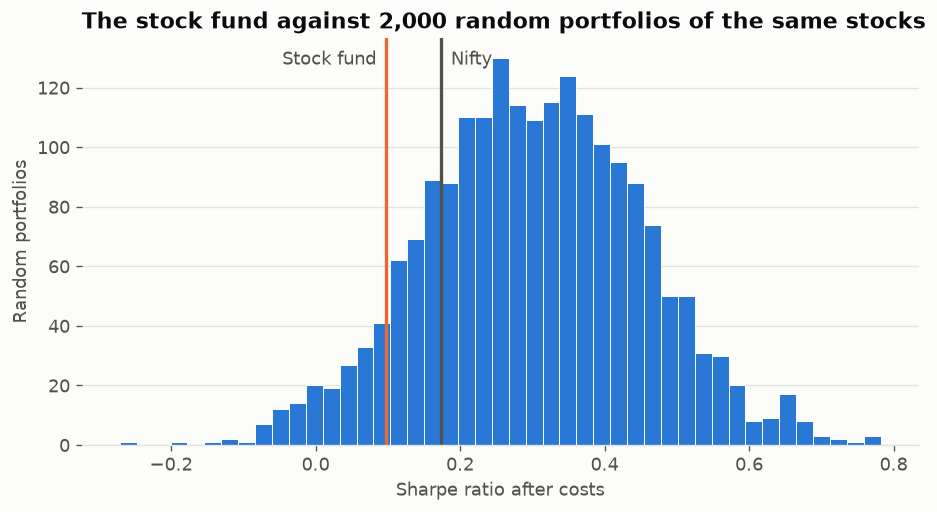

,sharpe,sharpe_percentile,drawdown,drawdown_percentile,volatility_percentile
Stock fund,0.098,0.084,-0.236,0.871,0.630
Capped lowest risk,-0.066,0.006,-0.300,0.998,0.516
Equal weight,0.329,0.568,-0.181,0.324,0.204
Market tracker,0.208,0.268,-0.208,0.651,0.132
Nifty,0.173,0.200,-0.199,0.548,0.042


In [6]:
rng = np.random.default_rng(41)
rows = []
for _ in range(2000):
    plan = {date: pd.Series(1 / 12, index=rng.choice(stocks, 12, replace=False)) for date in rebalance_dates}
    series = backtest.simulate(tested, plan, COSTS).returns - rf.loc[holdout]
    rows.append({"sharpe": series.mean() / series.std() * np.sqrt(12),
                 "max_drawdown": -stats.max_drawdown(series),
                 "volatility": series.std() * np.sqrt(12), "mean": series.mean() * 12})
random = pd.DataFrame(rows)
index = excess_net["Nifty"]
out = {}
for name in ["Stock fund", "Capped lowest risk", "Equal weight", "Market tracker", "Nifty"]:
    series = excess_net[name]
    sharpe = series.mean() / series.std() * np.sqrt(12)
    out[name] = {"sharpe": sharpe, "sharpe_percentile": perf.percentile_rank(sharpe, random["sharpe"]),
                 "drawdown": stats.max_drawdown(series),
                 "drawdown_percentile": perf.percentile_rank(-stats.max_drawdown(series), random["max_drawdown"]),
                 "volatility_percentile": perf.percentile_rank(series.std() * np.sqrt(12), random["volatility"])}
print(f"Random portfolios, median: Sharpe {random['sharpe'].median():.2f}, "
      f"drawdown {-random['max_drawdown'].median():.1%}, volatility {random['volatility'].median():.1%}")
chance = pd.DataFrame(out).T
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(random["sharpe"], bins=45, color=SERIES_1, edgecolor=SURFACE, linewidth=0.6)
top = ax.get_ylim()[1]
for name, color, shift, align in [("Stock fund", SERIES_2, -6, "right"), ("Nifty", MUTED, 6, "left")]:
    ax.axvline(chance.loc[name, "sharpe"], color=color, linewidth=2)
    ax.annotate(name, (chance.loc[name, "sharpe"], top * 0.97), xytext=(shift, 0),
                textcoords="offset points", ha=align, color=MUTED, va="top")
ax.set_xlabel("Sharpe ratio after costs")
ax.set_ylabel("Random portfolios")
ax.set_title("The stock fund against 2,000 random portfolios of the same stocks")
fig.savefig(FIGURES / "10_random_portfolios.png")
plt.show()
chance.round(3)

## 4. Did the model describe risk honestly?

Promised figures come from each rebalance, using only the data available then.

In [7]:
rows = []
for date in rebalance_dates:
    mean, cov, rate = fitted_inputs(training(date))
    weights = fund_weights(training(date))
    expected, volatility = fr.portfolio_stats(weights, mean - HAIRCUT, cov)
    months = holdout[(holdout >= date) & (holdout < date + pd.DateOffset(years=1))]
    held = net["Stock fund"].returns.loc[months]
    rows.append({"start": f"{date:%b %Y}", "promised_return": expected,
                 "realized_return": (1 + held).prod() - 1, "promised_vol": volatility,
                 "realized_vol": held.std() * np.sqrt(12), "t_bill_rate": rate})
pd.DataFrame(rows).set_index("start").round(3)

,promised_return,realized_return,promised_vol,realized_vol,t_bill_rate
start,,,,,
Nov 2023,0.138,0.277,0.144,0.166,0.048
Nov 2024,0.188,0.020,0.182,0.127,0.050
Nov 2025,0.202,-0.074,0.144,0.158,0.053


## 5. Applying the decision rules

In [8]:
maximum = card["max_drawdown"]
rule_1 = (maximum["Stock fund"] > maximum["Equal weight"] and maximum["Stock fund"] > maximum["Nifty"]
          and card.loc["Stock fund", "sharpe"] >= card.loc["Nifty", "sharpe"])
print(f"Rule 1, keep the stock fund as the default equity sleeve: {rule_1}")
print(f"  drawdown: fund {maximum['Stock fund']:.1%}, equal weight {maximum['Equal weight']:.1%}, Nifty {maximum['Nifty']:.1%}")
print(f"  Sharpe: fund {card.loc['Stock fund', 'sharpe']:.2f}, Nifty {card.loc['Nifty', 'sharpe']:.2f}")

for sleeve in ["stock fund", "Nifty"]:
    names = [f"{name}, {sleeve}" for name in POLICIES]
    draws = maximum[names]
    below_nifty = {name: bool(draws[name] > maximum["Nifty"]) for name in names}
    ordered = draws.iloc[0] > draws.iloc[1] > draws.iloc[2]
    print(f"Rule 2, policies with {sleeve}: better than Nifty {below_nifty}; ordered by risk {bool(ordered)}")
    print(f"  drawdowns {draws.round(3).to_dict()}")

claim = fair.loc["Stock fund", "alpha_t"] > 2 and chance.loc["Stock fund", "sharpe_percentile"] > 0.95
print(f"Rule 3, tool may claim outperformance: {bool(claim)}")

check = {name: stats.max_drawdown(net[name].returns) for name in
         ["Stock fund", "Equal weight", "Nifty", "Cautious, Nifty", "Balanced, Nifty", "Growth, Nifty"]}
print("Drawdowns above are in excess of T-bills. On total returns:", {k: round(v, 3) for k, v in check.items()})

Rule 1, keep the stock fund as the default equity sleeve: False
  drawdown: fund -23.6%, equal weight -18.1%, Nifty -19.9%
  Sharpe: fund 0.10, Nifty 0.17
Rule 2, policies with stock fund: better than Nifty {'Cautious, stock fund': True, 'Balanced, stock fund': True, 'Growth, stock fund': True}; ordered by risk True
  drawdowns {'Cautious, stock fund': -0.084, 'Balanced, stock fund': -0.121, 'Growth, stock fund': -0.167}
Rule 2, policies with Nifty: better than Nifty {'Cautious, Nifty': True, 'Balanced, Nifty': True, 'Growth, Nifty': True}; ordered by risk True
  drawdowns {'Cautious, Nifty': -0.078, 'Balanced, Nifty': -0.112, 'Growth, Nifty': -0.124}
Rule 3, tool may claim outperformance: False
Drawdowns above are in excess of T-bills. On total returns: {'Stock fund': -0.191, 'Equal weight': -0.152, 'Nifty': -0.145, 'Cautious, Nifty': -0.052, 'Balanced, Nifty': -0.086, 'Growth, Nifty': -0.103}


**The stock fund failed Rule 1**, so the tool's default equity sleeve becomes a Nifty ETF. The three
policies passed Rule 2 with either sleeve. Rule 3 stays closed: the tool makes no outperformance claim.

The rest of this notebook explains these results. None of it changes the method, because the holdout
can't be reused for tuning.

## 6. Why did the policies pass?

These checks look at what drove the result. The last two rows are diagnostics only, showing how far
the policy results depended on gold.

In [9]:
sleeves = pd.DataFrame({
    "cagr": tested[[market, "Gold", "Bonds", "Cash"]].apply(stats.geometric_return),
    "volatility": tested[[market, "Gold", "Bonds", "Cash"]].std() * np.sqrt(12),
    "max_drawdown": tested[[market, "Gold", "Bonds", "Cash"]].apply(stats.max_drawdown),
})
print(sleeves.round(3))
print(f"Correlation of Nifty and gold in the holdout: {tested[market].corr(tested['Gold']):.2f}")

diagnostic = {"Balanced, Nifty (as tested)": policy(nifty, (0.6, 0.2, 0.2)),
              "Same with gold moved to bonds": policy(nifty, (0.6, 0.0, 0.4))}
rows = {}
for name, weights in diagnostic.items():
    series = backtest.simulate(tested, {d: weights for d in rebalance_dates}, COSTS).returns
    extra = series - rf.loc[holdout]
    rows[name] = {"cagr": stats.geometric_return(series), "volatility": extra.std() * np.sqrt(12),
                  "sharpe": extra.mean() / extra.std() * np.sqrt(12),
                  "max_drawdown": stats.max_drawdown(extra)}
pd.DataFrame(rows).T.round(3)

            cagr  volatility  max_drawdown
NIFTYBEES  0.076       0.137        -0.145
Gold       0.303       0.189        -0.124
Bonds      0.061       0.032        -0.024
Cash       0.061       0.002         0.000
Correlation of Nifty and gold in the holdout: 0.05


,cagr,volatility,sharpe,max_drawdown
"Balanced, Nifty (as tested)",0.121,0.096,0.629,-0.112
Same with gold moved to bonds,0.072,0.090,0.160,-0.132


## 7. Why did the stock fund fail?

This compares each year's fund with the Nifty, and shows the sectors it favored.

In [10]:
sectors = data.universe.set_index("symbol")["sector"]
rows = []
for date, weights in plans["Stock fund"].items():
    months = holdout[(holdout >= date) & (holdout < date + pd.DateOffset(years=1))]
    top = weights.groupby(sectors).sum().sort_values(ascending=False).head(2)
    rows.append({"start": f"{date:%b %Y}",
                 "fund": (1 + net["Stock fund"].returns.loc[months]).prod() - 1,
                 "nifty": (1 + net["Nifty"].returns.loc[months]).prod() - 1,
                 "equal_weight": (1 + net["Equal weight"].returns.loc[months]).prod() - 1,
                 "largest_sectors": ", ".join(f"{name} {value:.0%}" for name, value in top.items())})
pd.DataFrame(rows).set_index("start").round(3)

,fund,nifty,equal_weight,largest_sectors
start,,,,
Nov 2023,0.277,0.282,0.316,"Information Technology 21%, Consumer 20%"
Nov 2024,0.020,0.076,0.082,"Healthcare 20%, Automobile 20%"
Nov 2025,-0.074,-0.097,-0.065,"Automobile 27%, Telecom 10%"


## Stage 10 conclusions

1. **The stock fund did not hold up.** After costs it lagged the Nifty and equal weight, with a deeper
   drawdown. Its yearly promises were also poor, with realized returns well away from them each year.
2. **The Stage 8 result didn't survive either.** The drawdown control seen in the estimation period
   wasn't there in the holdout, and the capped lowest-risk portfolio had the worst drawdown of all.
3. **Asset allocation did hold up.** All three policies beat the Nifty on drawdown and Sharpe, and their
   drawdowns were ordered by risk as intended. The asset mix mattered far more than the stock mix.
4. **Gold did much of the work.** It compounded at about 30% a year, which should not be expected
   again. With gold moved to bonds, Balanced's Sharpe falls to about the Nifty's, though its drawdown
   stays much smaller. So the risk reduction is more dependable than the return.
5. **Costs were small and tax modest.** Yearly rebalancing kept costs near 0.2% a year or less.
6. **36 months is short.** The fund's gap to the Nifty is within noise, so this doesn't prove the fund
   is worse. The rule was fixed in advance and it is applied as written.

### Decisions for the final tool

- **Default equity sleeve:** a Nifty ETF. It's cheaper, simpler and didn't lose to the fund. A
  stock-level portfolio can appear as an optional mode, with these results shown beside it.
- **Policies:** Cautious 25/15/60, Balanced 60/20/20, Growth 80/10/10, unchanged.
- **Messaging:** no outperformance claims. The tool's value is a disciplined, diversified allocation
  that matches an investor's risk, with honest ranges and loss estimates.